# ParkWise Weather: exploratory data analysis

Daily weather for the 63 U.S. National Parks, 2015–2025, from the Open-Meteo archive
(ERA5 reanalysis) at each park's weather point. This notebook asks the questions that
shape the Phase 3 models:

1. Is the data complete and plausible?
2. How strong is the seasonal cycle, and how different are the parks?
3. How noisy is a single day around its seasonal normal? (This sets the floor on how
   accurate any months-ahead estimate can be.)
4. Does today's weather say anything about weather weeks from now? (If not, a climate
   estimate can't use recent observations.)
5. Is there a trend across 2015–2025?

Run from the project root with the backend venv:
`backend/.venv/bin/jupyter nbconvert --to notebook --execute --inplace notebooks/01_eda.ipynb`

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "backend"))   # so `import app` works from notebooks/

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from app.database.connection import SessionLocal
from scripts.train_models import load_history

pd.set_option("display.precision", 2)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False})

with SessionLocal() as db:
    df = load_history(db)
df["date"] = pd.to_datetime(df["date"])
df["year"], df["month"], df["doy"] = df["date"].dt.year, df["date"].dt.month, df["date"].dt.day_of_year
df["wet"] = (df["precipitation"] >= 1.0).astype(float)
print(f"{len(df):,} rows, {df['park_code'].nunique()} parks, {df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")

229,407 rows, 63 parks, 2016-01-01 to 2025-12-31


## 1. Completeness and plausibility

In [2]:
coverage = df.groupby("park_code").agg(days=("date", "size"), first=("date", "min"), last=("date", "max"))
expected = (pd.Timestamp("2025-12-31") - pd.Timestamp("2015-01-01")).days + 1
print(f"Parks with all {expected:,} days: {(coverage['days'] == expected).sum()} of {len(coverage)}")
print("Missing values per column:")
print(df[["temp_max", "temp_min", "precipitation", "snowfall", "wind_speed_max"]].isna().sum().to_string())
df[["temp_max", "temp_min", "precipitation", "snowfall", "wind_speed_max"]].describe().T

Parks with all 4,018 days: 0 of 63
Missing values per column:
temp_max          0
temp_min          0
precipitation     0
snowfall          0
wind_speed_max    0


,count,mean,std,min,25%,50%,75%,max
temp_max,229407.0,15.80,12.15,-39.5,7.1,16.8,25.7,51.70
temp_min,229407.0,6.50,11.48,-42.7,-1.3,6.7,14.6,40.50
precipitation,229407.0,2.76,7.42,0.0,0.0,0.0,1.9,283.90
snowfall,229407.0,0.33,1.86,0.0,0.0,0.0,0.0,80.01
wind_speed_max,229407.0,17.26,8.36,0.8,11.0,15.6,22.0,144.60


## 2. Seasonal cycle and differences between parks

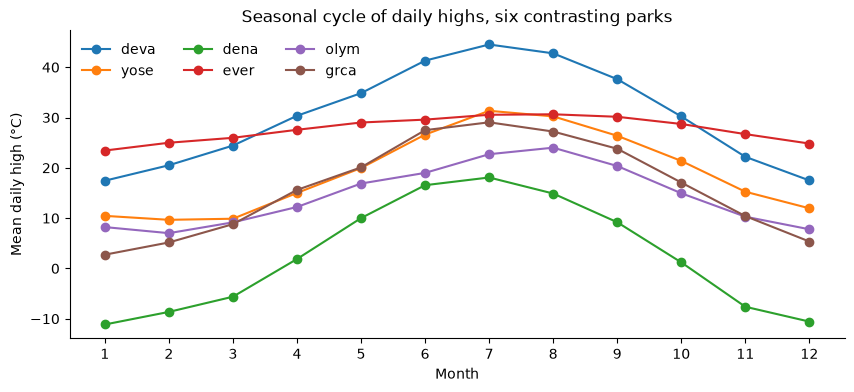

Seasonal amplitude of monthly mean highs: median 23.2 °C, range 1.4 (npsa) to 33.2 (voya) °C


In [3]:
monthly = df.groupby(["park_code", "month"])["temp_max"].mean().unstack()
examples = ["deva", "yose", "dena", "ever", "olym", "grca"]
fig, ax = plt.subplots()
for code in examples:
    ax.plot(range(1, 13), monthly.loc[code], marker="o", label=code)
ax.set(xlabel="Month", ylabel="Mean daily high (°C)", title="Seasonal cycle of daily highs, six contrasting parks",
       xticks=range(1, 13))
ax.legend(ncol=3, frameon=False)
plt.show()

annual = df.groupby("park_code")["temp_max"].agg(["mean", "std"])
amplitude = monthly.max(axis=1) - monthly.min(axis=1)
print(f"Seasonal amplitude of monthly mean highs: median {amplitude.median():.1f} °C, "
      f"range {amplitude.min():.1f} ({amplitude.idxmin()}) to {amplitude.max():.1f} ({amplitude.idxmax()}) °C")

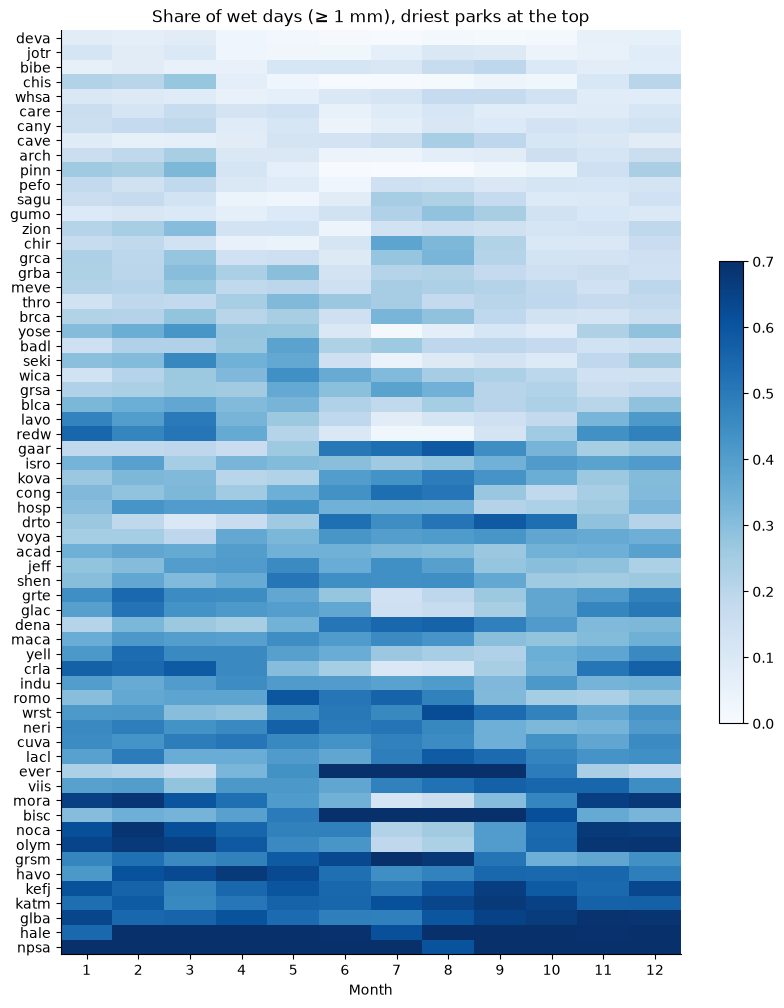

In [4]:
wet_by_month = df.groupby(["park_code", "month"])["wet"].mean().unstack()
order = wet_by_month.mean(axis=1).sort_values().index
fig, ax = plt.subplots(figsize=(10, 12))
im = ax.imshow(wet_by_month.loc[order], aspect="auto", cmap="Blues", vmin=0, vmax=0.7)
ax.set(yticks=range(len(order)), yticklabels=order, xticks=range(12), xticklabels=range(1, 13),
       xlabel="Month", title="Share of wet days (≥ 1 mm), driest parks at the top")
fig.colorbar(im, ax=ax, shrink=0.5)
plt.show()

## 3. Day-to-day noise around the seasonal normal

If we knew each park's exact normal for every day of the year, how far would a single
day still be from it? That spread is the error floor for any climate estimate.

Daily-high anomaly, mean absolute size: median 3.22 °C across parks (0.46 in viis to 5.05 in thro)


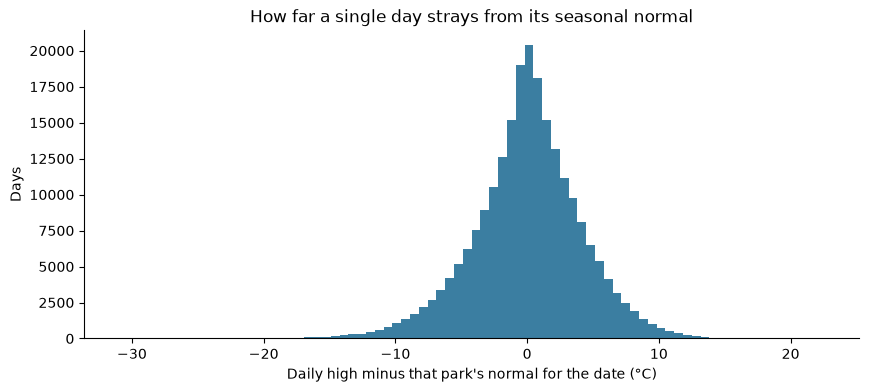

In [5]:
normal = df.groupby(["park_code", "doy"])["temp_max"].transform("mean")
df["anomaly"] = df["temp_max"] - normal
spread = df.groupby("park_code")["anomaly"].agg(sd="std", mae=lambda a: a.abs().mean())
print(f"Daily-high anomaly, mean absolute size: median {spread['mae'].median():.2f} °C across parks "
      f"({spread['mae'].min():.2f} in {spread['mae'].idxmin()} to {spread['mae'].max():.2f} in {spread['mae'].idxmax()})")
fig, ax = plt.subplots()
ax.hist(df["anomaly"].dropna(), bins=80, color="#3b7ea1")
ax.set(xlabel="Daily high minus that park's normal for the date (°C)", ylabel="Days",
       title="How far a single day strays from its seasonal normal")
plt.show()

## 4. Does today's weather predict weeks ahead?

Autocorrelation of the daily-high anomaly, averaged over parks. A high value at lag *k*
means a warm-for-the-season day tends to be followed by another one *k* days later.

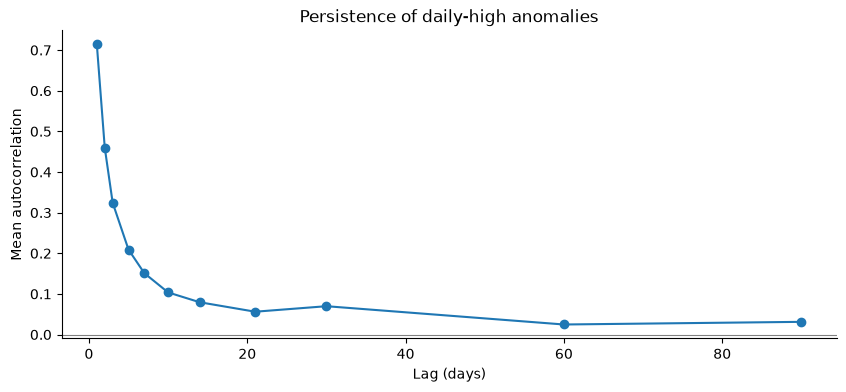

,autocorrelation
1,0.71
2,0.46
3,0.32
5,0.21
7,0.15
10,0.10
14,0.08
21,0.06
30,0.07
60,0.03


In [6]:
lags = [1, 2, 3, 5, 7, 10, 14, 21, 30, 60, 90]
acf = pd.DataFrame({
    code: [g.sort_values("date")["anomaly"].autocorr(lag) for lag in lags]
    for code, g in df.groupby("park_code")
}, index=lags).mean(axis=1)
fig, ax = plt.subplots()
ax.plot(acf.index, acf.values, marker="o")
ax.axhline(0, color="grey", lw=0.8)
ax.set(xlabel="Lag (days)", ylabel="Mean autocorrelation", title="Persistence of daily-high anomalies")
plt.show()
acf.round(3).to_frame("autocorrelation")

## 5. Trend across 2015–2025

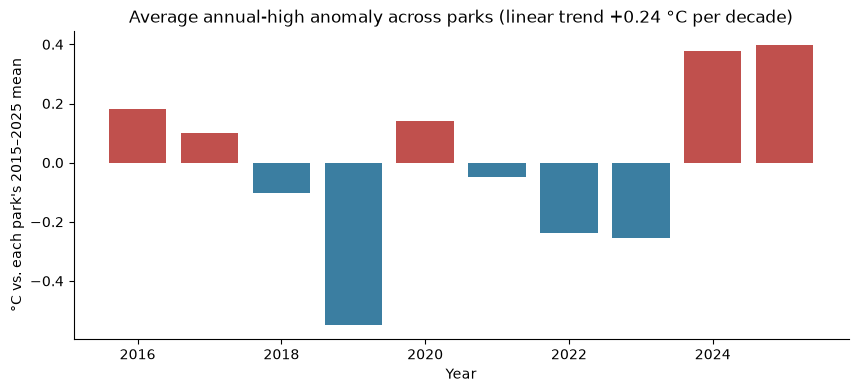

In [7]:
yearly = df.groupby(["park_code", "year"])["temp_max"].mean().unstack()
yearly_anom = yearly.sub(yearly.mean(axis=1), axis=0).mean()
slope = np.polyfit(yearly_anom.index, yearly_anom.values, 1)[0]
fig, ax = plt.subplots()
ax.bar(yearly_anom.index, yearly_anom.values, color=np.where(yearly_anom > 0, "#c0504d", "#3b7ea1"))
ax.set(xlabel="Year", ylabel="°C vs. each park's 2015–2025 mean",
       title=f"Average annual-high anomaly across parks (linear trend {slope * 10:+.2f} °C per decade)")
plt.show()

## Findings and what they mean for the models

In [8]:
print(f"1. Data: {len(df):,} rows; parks complete: {(coverage['days'] == expected).sum()}/{len(coverage)}.")
print(f"2. Seasonal amplitude (median) {amplitude.median():.1f} °C: the seasonal cycle dominates, "
      "so every model is built around it.")
print(f"3. A single day misses its normal by {spread['mae'].median():.1f} °C on average: "
      "no months-ahead model can be much more accurate than this.")
print(f"4. Anomaly autocorrelation falls to {acf.loc[14]:.2f} at 14 days and {acf.loc[30]:.2f} at 30 days: "
      "beyond the forecast window, recent weather carries almost no information, "
      "so climate models use only date and place.")
print(f"5. Trend {slope * 10:+.2f} °C per decade across parks: small next to day-to-day noise, "
      "but a model with a trend term can capture it.")

1. Data: 229,407 rows; parks complete: 0/63.
2. Seasonal amplitude (median) 23.2 °C: the seasonal cycle dominates, so every model is built around it.
3. A single day misses its normal by 3.2 °C on average: no months-ahead model can be much more accurate than this.
4. Anomaly autocorrelation falls to 0.08 at 14 days and 0.07 at 30 days: beyond the forecast window, recent weather carries almost no information, so climate models use only date and place.
5. Trend +0.24 °C per decade across parks: small next to day-to-day noise, but a model with a trend term can capture it.
